# 02 — A/B Testing and Revenue Bootstrap

This notebook explains the randomized experiment and loads the actual statistical outputs produced by the reusable testing modules.

Primary outcome: website visit. Secondary outcomes: purchase conversion and revenue per assigned customer.

In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
import pandas as pd
import matplotlib.pyplot as plt
results = pd.read_csv(ROOT / "reports/ab_test_results.csv")
revenue = pd.read_csv(ROOT / "reports/revenue_bootstrap_results.csv")
results

,outcome,analysis_type,treatment_group,control_group,treatment_n,control_n,treatment_events,control_events,treatment_rate,control_rate,absolute_effect_percentage_points,relative_lift_percentage,z_statistic,unadjusted_p_value,holm_adjusted_p_value,confidence_interval_low_percentage_points,confidence_interval_high_percentage_points,reject_null_after_holm
0,visit,primary,Mens E-Mail,No E-Mail,21307,21306,3894,2262,0.182757,0.106167,7.658956,72.140462,22.486041,5.685165e-112,1.137033e-111,6.995350,8.322563,True
1,visit,primary,Womens E-Mail,No E-Mail,21387,21306,3238,2262,0.151400,0.106167,4.523311,42.605507,13.949181,3.182403e-44,3.182403e-44,3.889383,5.157239,True
2,conversion,exploratory_secondary,Mens E-Mail,No E-Mail,21307,21306,267,122,0.012531,0.005726,0.680501,118.842188,7.385114,1.523224e-13,3.046447e-13,0.500017,0.860984,True
3,conversion,exploratory_secondary,Womens E-Mail,No E-Mail,21387,21306,189,122,0.008837,0.005726,0.311106,54.331304,3.779561,1.571051e-04,1.571051e-04,0.149868,0.472344,True


## Experimental design and hypotheses

For each treatment-versus-control comparison, the null hypothesis is that the treatment and control visit rates are equal. The alternative hypothesis is that they differ. The primary significance level is alpha = 0.05, with Holm correction for the two treatment comparisons sharing the control group.

A percentage-point effect is treatment rate minus control rate; it is not the same as relative lift. A confidence interval gives a plausible range for the effect under the analysis method. Statistical significance does not establish profitability.

In [2]:
primary = results[results.analysis_type == "primary"].copy()
primary[["treatment_group", "treatment_rate", "control_rate", "absolute_effect_percentage_points", "holm_adjusted_p_value", "confidence_interval_low_percentage_points", "confidence_interval_high_percentage_points", "reject_null_after_holm"]]

,treatment_group,treatment_rate,control_rate,absolute_effect_percentage_points,holm_adjusted_p_value,confidence_interval_low_percentage_points,confidence_interval_high_percentage_points,reject_null_after_holm
0,Mens E-Mail,0.182757,0.106167,7.658956,1.137033e-111,6.995350,8.322563,True
1,Womens E-Mail,0.151400,0.106167,4.523311,3.182403e-44,3.889383,5.157239,True


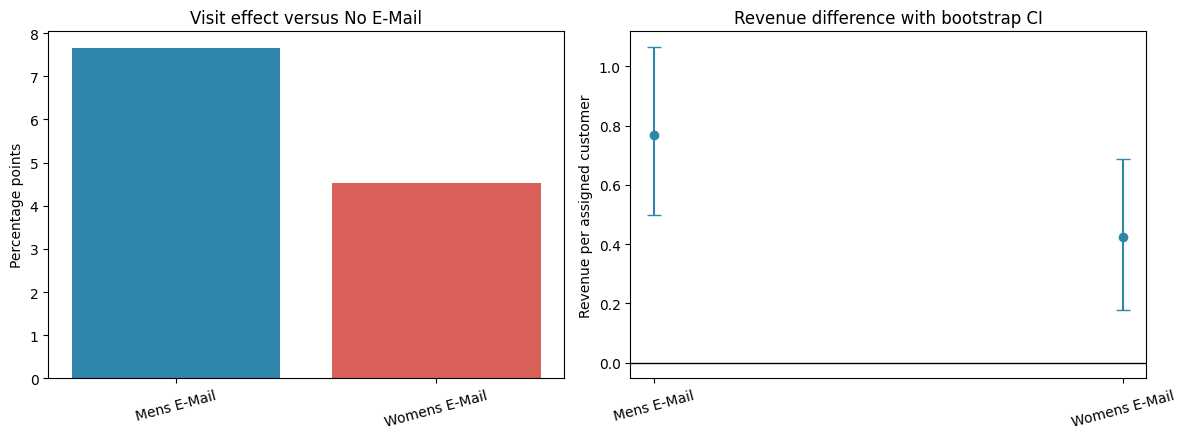

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(primary.treatment_group, primary.absolute_effect_percentage_points, color=["#2E86AB", "#D95F59"])
axes[0].set(title="Visit effect versus No E-Mail", ylabel="Percentage points")
axes[1].errorbar(revenue.treatment_group, revenue.observed_difference, yerr=[revenue.observed_difference-revenue.confidence_interval_low, revenue.confidence_interval_high-revenue.observed_difference], fmt="o", capsize=5, color="#2E86AB")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Revenue difference with bootstrap CI", ylabel="Revenue per assigned customer")
for axis in axes: axis.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## Bootstrap intuition

The revenue analysis resamples complete customers within each randomized group 2,000 times, calculates the treatment-control mean difference each time, and uses the middle 95% of those differences as a percentile interval. This keeps zero-spend customers in the denominator and reflects the strong skew in spending.

## Key Findings

- Both primary visit comparisons remain significant after Holm correction.
- Mens E-Mail has the larger visit and conversion effect.
- Revenue differences versus No E-Mail have bootstrap intervals above zero.
- Revenue increases are not ROI or profitability estimates because campaign costs and margins are unavailable.